<h1 style="text-align: center;">Model Experimentation</h1>

## Purpose

This notebook explores and compares machine learning models for predicting football match outcomes (**Home Win, Draw, Away Win**) using information available **before kickoff**.

## Short Explanation

Starting from `Data/model_data_raw.parquet`, we will investigate appropriate validation and leakage-safe preprocessing, establish baseline models, and compare model performance **with and without bookmaker odds**. Experiments and decisions will be documented as we progress; no model or feature selection is assumed in advance.

---

In [85]:
import pandas as pd
pd.set_option('display.precision',3)

In [86]:
data_v1 = pd.read_parquet("../Data/model_data_raw.parquet")

In [9]:
data_v1.head()

,home_team_long_name,away_team_long_name,home_buildUpPlaySpeed,home_buildUpPlaySpeedClass,home_buildUpPlayDribblingClass,home_buildUpPlayPassing,home_buildUpPlayPassingClass,home_buildUpPlayPositioningClass,home_chanceCreationPassing,home_chanceCreationPassingClass,...,B365H,B365D,B365A,BWH,BWD,BWA,LBH,LBD,LBA,FTR
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.73,3.40,5.00,1.75,3.35,4.20,1.80,3.3,3.75,D
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.95,3.20,3.60,1.80,3.30,3.95,1.90,3.2,3.50,D
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.38,3.30,2.75,2.40,3.30,2.55,2.50,3.2,2.50,A
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.44,3.75,7.50,1.40,4.00,6.80,1.44,3.6,6.50,H
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5.00,3.50,1.65,5.00,3.50,1.60,4.00,3.4,1.72,A


In [10]:
data_v1.shape

(25979, 52)

----

## Preprocessing Dataset version 1

### Inspection

In [11]:
data_v1.duplicated().sum()

np.int64(1330)

In [12]:
data_v1.isna().sum()

home_team_long_name                    7163
away_team_long_name                    7165
home_buildUpPlaySpeed                  7163
home_buildUpPlaySpeedClass             7163
home_buildUpPlayDribblingClass         7163
home_buildUpPlayPassing                7163
home_buildUpPlayPassingClass           7163
home_buildUpPlayPositioningClass       7163
home_chanceCreationPassing             7163
home_chanceCreationPassingClass        7163
home_chanceCreationCrossing            7163
home_chanceCreationCrossingClass       7163
home_chanceCreationShooting            7163
home_chanceCreationShootingClass       7163
home_chanceCreationPositioningClass    7163
home_defencePressure                   7163
home_defencePressureClass              7163
home_defenceAggression                 7163
home_defenceAggressionClass            7163
home_defenceTeamWidth                  7163
home_defenceTeamWidthClass             7163
home_defenceDefenderLineClass          7163
away_buildUpPlaySpeed           

In [13]:
(data_v1.isna().mean())*100

home_team_long_name                    27.572
away_team_long_name                    27.580
home_buildUpPlaySpeed                  27.572
home_buildUpPlaySpeedClass             27.572
home_buildUpPlayDribblingClass         27.572
home_buildUpPlayPassing                27.572
home_buildUpPlayPassingClass           27.572
home_buildUpPlayPositioningClass       27.572
home_chanceCreationPassing             27.572
home_chanceCreationPassingClass        27.572
home_chanceCreationCrossing            27.572
home_chanceCreationCrossingClass       27.572
home_chanceCreationShooting            27.572
home_chanceCreationShootingClass       27.572
home_chanceCreationPositioningClass    27.572
home_defencePressure                   27.572
home_defencePressureClass              27.572
home_defenceAggression                 27.572
home_defenceAggressionClass            27.572
home_defenceTeamWidth                  27.572
home_defenceTeamWidthClass             27.572
home_defenceDefenderLineClass     

In [14]:
data_v1.nunique()

home_team_long_name                    277
away_team_long_name                    277
home_buildUpPlaySpeed                   56
home_buildUpPlaySpeedClass               3
home_buildUpPlayDribblingClass           3
home_buildUpPlayPassing                 57
home_buildUpPlayPassingClass             3
home_buildUpPlayPositioningClass         2
home_chanceCreationPassing              50
home_chanceCreationPassingClass          3
home_chanceCreationCrossing             56
home_chanceCreationCrossingClass         3
home_chanceCreationShooting             57
home_chanceCreationShootingClass         3
home_chanceCreationPositioningClass      2
home_defencePressure                    48
home_defencePressureClass                3
home_defenceAggression                  46
home_defenceAggressionClass              3
home_defenceTeamWidth                   43
home_defenceTeamWidthClass               3
home_defenceDefenderLineClass            2
away_buildUpPlaySpeed                   56
away_buildU

In [15]:
data_v1.dtypes

home_team_long_name                        str
away_team_long_name                        str
home_buildUpPlaySpeed                  float64
home_buildUpPlaySpeedClass                 str
home_buildUpPlayDribblingClass             str
home_buildUpPlayPassing                float64
home_buildUpPlayPassingClass               str
home_buildUpPlayPositioningClass           str
home_chanceCreationPassing             float64
home_chanceCreationPassingClass            str
home_chanceCreationCrossing            float64
home_chanceCreationCrossingClass           str
home_chanceCreationShooting            float64
home_chanceCreationShootingClass           str
home_chanceCreationPositioningClass        str
home_defencePressure                   float64
home_defencePressureClass                  str
home_defenceAggression                 float64
home_defenceAggressionClass                str
home_defenceTeamWidth                  float64
home_defenceTeamWidthClass                 str
home_defenceD

---

In [87]:
x = data_v1.drop(columns=["FTR"]).copy()
y = data_v1["FTR"].map({"A": 0, "D": 1, "H": 2})


cat_cols = x.select_dtypes(include=["object", "string"]).columns
x[cat_cols] = x[cat_cols].astype("category")

In [88]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x ,y, test_size=0.3, random_state=1)

In [89]:
import mlflow

dataset_v1 = mlflow.data.from_pandas(
    data_v1,
    name="dataset_v1",
    targets="FTR"
)

---

## Experiment 1: XGBoost

XGBoost is selected for our first experiment because it natively handles missing values and supports categorical features without manual encoding. The objective is to establish an initial performance benchmark for predicting pre-match football outcomes, with results tracked using MLflow.

In [ ]:
from xgboost import XGBClassifier

In [19]:
model_1 = XGBClassifier(n_estimators=150, max_depth=8, learning_rate=0.1, min_child_weight=20, gamma=0, enable_categorical=True, random_state=1)

In [20]:
model_1.fit(x_train, y_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

In [21]:
y_hat = model_1.predict(x_test)
y_hat_train = model_1.predict(x_train)

Evaluation

In [90]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
print(f"Accuracy of the model is {accuracy_score(y_test, y_hat)}")
print(f"Accuracy of the model is {accuracy_score(y_train, y_hat_train)}")

Accuracy of the model is 0.4722863741339492
Accuracy of the model is 0.8391531481990652


In [24]:
print("classification_report")
print(classification_report(y_test, y_hat))

classification_report
              precision    recall  f1-score   support

           0       0.43      0.40      0.41      2248
           1       0.26      0.17      0.20      1921
           2       0.55      0.68      0.61      3625

    accuracy                           0.47      7794
   macro avg       0.41      0.41      0.41      7794
weighted avg       0.44      0.47      0.45      7794



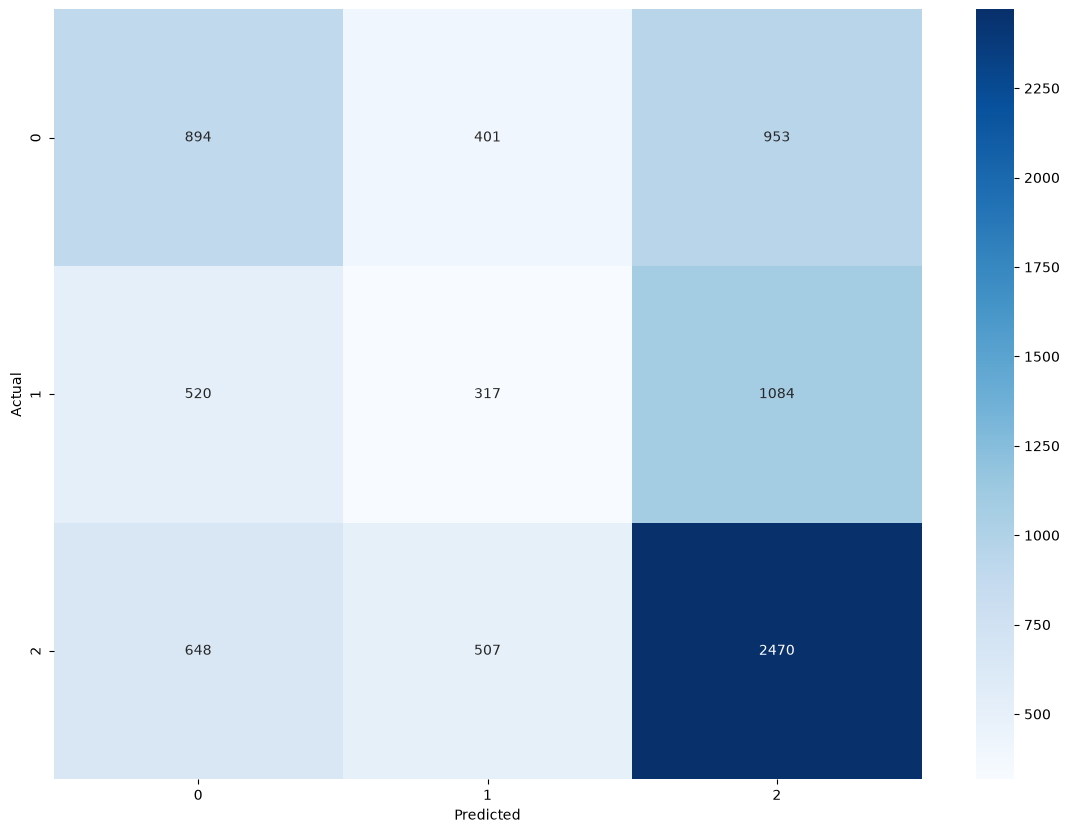

In [25]:
cm = confusion_matrix(y_test, y_hat)
plt.figure(figsize=(14,10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Football_match_prediction")
mlflow.set_tracking_uri("http://127.0.0.1:5000")


with mlflow.start_run(run_name="xgboost experiment 1"):
    mlflow.log_input(dataset_v1, context="source")
    mlflow.log_params(model_1.get_params())

    mlflow.log_metrics({
    "train_accuracy": 0.8391531481990652,
    "test_accuracy": 0.4722863741339492,

    "precision_away": 0.43,
    "recall_away": 0.40,

    "precision_draw": 0.26,
    "recall_draw": 0.17,

    "precision_home": 0.55,
    "recall_home": 0.68
}
)

    mlflow.xgboost.log_model(model_1, name="XGBClassifier_r1")



### Experiment 1: Evaluation

The initial XGBoost model shows significant overfitting, with training accuracy of 83.92% compared to test accuracy of 47.23%. Performance is particularly weak for draws (Class 1), with a recall of just 17%. This experiment establishes our initial benchmark. Future experiments will focus on hyperparameter tuning to reduce overfitting and improve overall accuracy and class-wise recall.

---

## Experiment 2: XGBoost — Max Depth Tuning

This experiment investigates the impact of `max_depth` on XGBoost's performance by testing depths of 3, 4, 6, and 8 while keeping other hyperparameters unchanged. The objective is to reduce overfitting and improve generalization, focusing on overall accuracy and class-wise recall, particularly for draws (Class 1).

In [ ]:
model_2 = XGBClassifier(n_estimators=150, max_depth=8, learning_rate=0.1, min_child_weight=20, gamma=0, enable_categorical=True, random_state=1)

In [ ]:
model_2.fit(x_train, y_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

In [ ]:
y_hat = model_2.predict(x_test)
y_hat_train = model_2.predict(x_train)

Evaluation

In [ ]:
print(f"Accuracy of the model is {accuracy_score(y_test, y_hat)}")
print(f"Train Accuracy of the model is {accuracy_score(y_train, y_hat_train)}")

Accuracy of the model is 0.4722863741339492
Train Accuracy of the model is 0.8391531481990652


In [ ]:
print("classification_report")
print(classification_report(y_test, y_hat))

classification_report
              precision    recall  f1-score   support

           0       0.43      0.40      0.41      2248
           1       0.26      0.17      0.20      1921
           2       0.55      0.68      0.61      3625

    accuracy                           0.47      7794
   macro avg       0.41      0.41      0.41      7794
weighted avg       0.44      0.47      0.45      7794



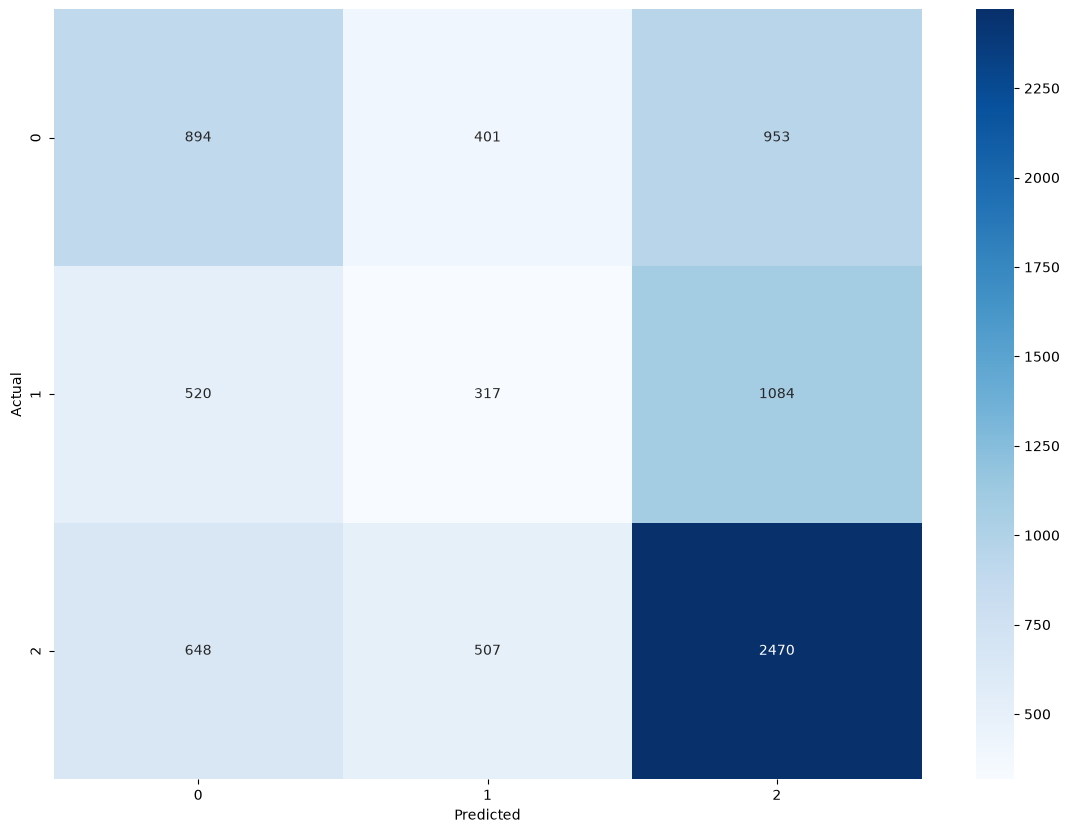

In [ ]:
cm = confusion_matrix(y_test, y_hat)
plt.figure(figsize=(14,10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Football_match_prediction")

with mlflow.start_run(run_name="xgboost experiment 2"):
    mlflow.log_input(dataset_v1, context="source")
    mlflow.log_params(model_2.get_params())

    mlflow.log_metrics({
    "train_accuracy": 0.8391531481990652,
    "test_accuracy": 0.4722863741339492,

    "precision_away": 0.43,
    "recall_away": 0.40,

    "precision_draw": 0.26,
    "recall_draw": 0.17,

    "precision_home": 0.55,
    "recall_home": 0.68
}
)

    mlflow.xgboost.log_model(model_2, name="XGBClassifier_r2")



🏃 View run xgboost experiment 2 at: http://127.0.0.1:5000/#/experiments/1/runs/08efa8eaa88542338828daae6425320b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


### Experiment 2: Evaluation

Among the tested values, `max_depth=8` delivered the best overall performance, with more balanced results across all three classes. Reducing tree depth did not improve generalization or class-wise recall, so a depth of 8 remains the preferred choice for further experiments.

---

## Experiment 3: XGBoost — Regularization Tuning

This experiment investigates `min_child_weight`, `gamma`, and `reg_lambda` while retaining `max_depth=8`. The objective is to reduce overfitting through stronger model restrictions and identify the best configuration based on overall accuracy and class-wise recall.

In [ ]:
model_3 = XGBClassifier(n_estimators=150, max_depth=8, learning_rate=0.1, min_child_weight=5, gamma=0, reg_alpha=0, reg_lambda=1 ,enable_categorical=True, random_state=1)

In [ ]:
model_3.fit(x_train, y_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

In [ ]:
y_hat = model_3.predict(x_test)
y_hat_train = model_3.predict(x_train)

Evaluation

In [ ]:
print(f"Accuracy of the model is {accuracy_score(y_test, y_hat)}")
print(f"Train Accuracy of the model is {accuracy_score(y_train, y_hat_train)}")

Accuracy of the model is 0.472671285604311
Train Accuracy of the model is 0.852075886719824


In [ ]:
print("classification_report")
print(classification_report(y_test, y_hat))

classification_report
              precision    recall  f1-score   support

           0       0.43      0.39      0.41      2248
           1       0.26      0.16      0.20      1921
           2       0.55      0.68      0.61      3625

    accuracy                           0.47      7794
   macro avg       0.41      0.41      0.41      7794
weighted avg       0.44      0.47      0.45      7794



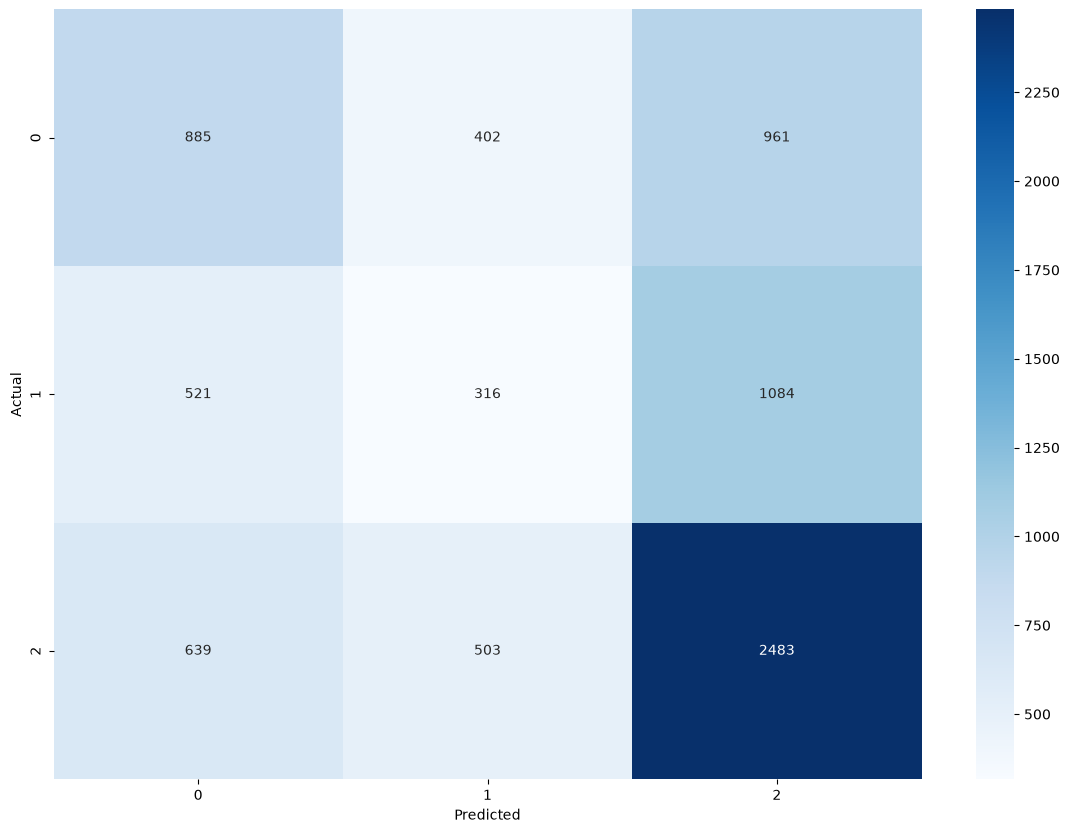

In [ ]:
cm = confusion_matrix(y_test, y_hat)
plt.figure(figsize=(14,10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Football_match_prediction")

with mlflow.start_run(run_name="xgboost experiment 3"):
    mlflow.log_input(dataset_v1, context="source")
    mlflow.log_params(model_3.get_params())

    mlflow.log_metrics({
    "train_accuracy": 0.852075886719824,
    "test_accuracy": 0.472671285604311,

    "precision_away": 0.43,
    "recall_away": 0.39,

    "precision_draw": 0.26,
    "recall_draw": 0.16,

    "precision_home": 0.55,
    "recall_home": 0.68
}
)

    mlflow.xgboost.log_model(model_3, name="XGBClassifier_r3")



🏃 View run xgboost experiment 3 at: http://127.0.0.1:5000/#/experiments/1/runs/b1ebafef60ec4b00a540581804d9b133
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


### Experiment 3: Evaluation

Regularization tuning (`min_child_weight`, `gamma`, `reg_lambda`, and `reg_alpha`) produced no meaningful overall improvement. The model still shows significant overfitting, with 85.21% training accuracy and 47.27% test accuracy. Stronger L1 regularization and gamma reduced overfitting but compromised Class 1 (Draw) recall. Overall, regularization alone was insufficient to improve generalization and balanced class performance.

---

## XGBoost Feature Importance Analysis

Feature importance was extracted from the baseline XGBoost model to identify which variables contributed most to its predictions.



In [ ]:
XGBoost_feature_importance = pd.DataFrame()

In [ ]:
XGBoost_feature_importance["Columns"] = x.columns

In [ ]:
XGBoost_feature_importance["importance"] = model_1.feature_importances_*100

In [ ]:
XGBoost_feature_importance = XGBoost_feature_importance.sort_values(by="importance", ascending=False).reset_index(drop=True)

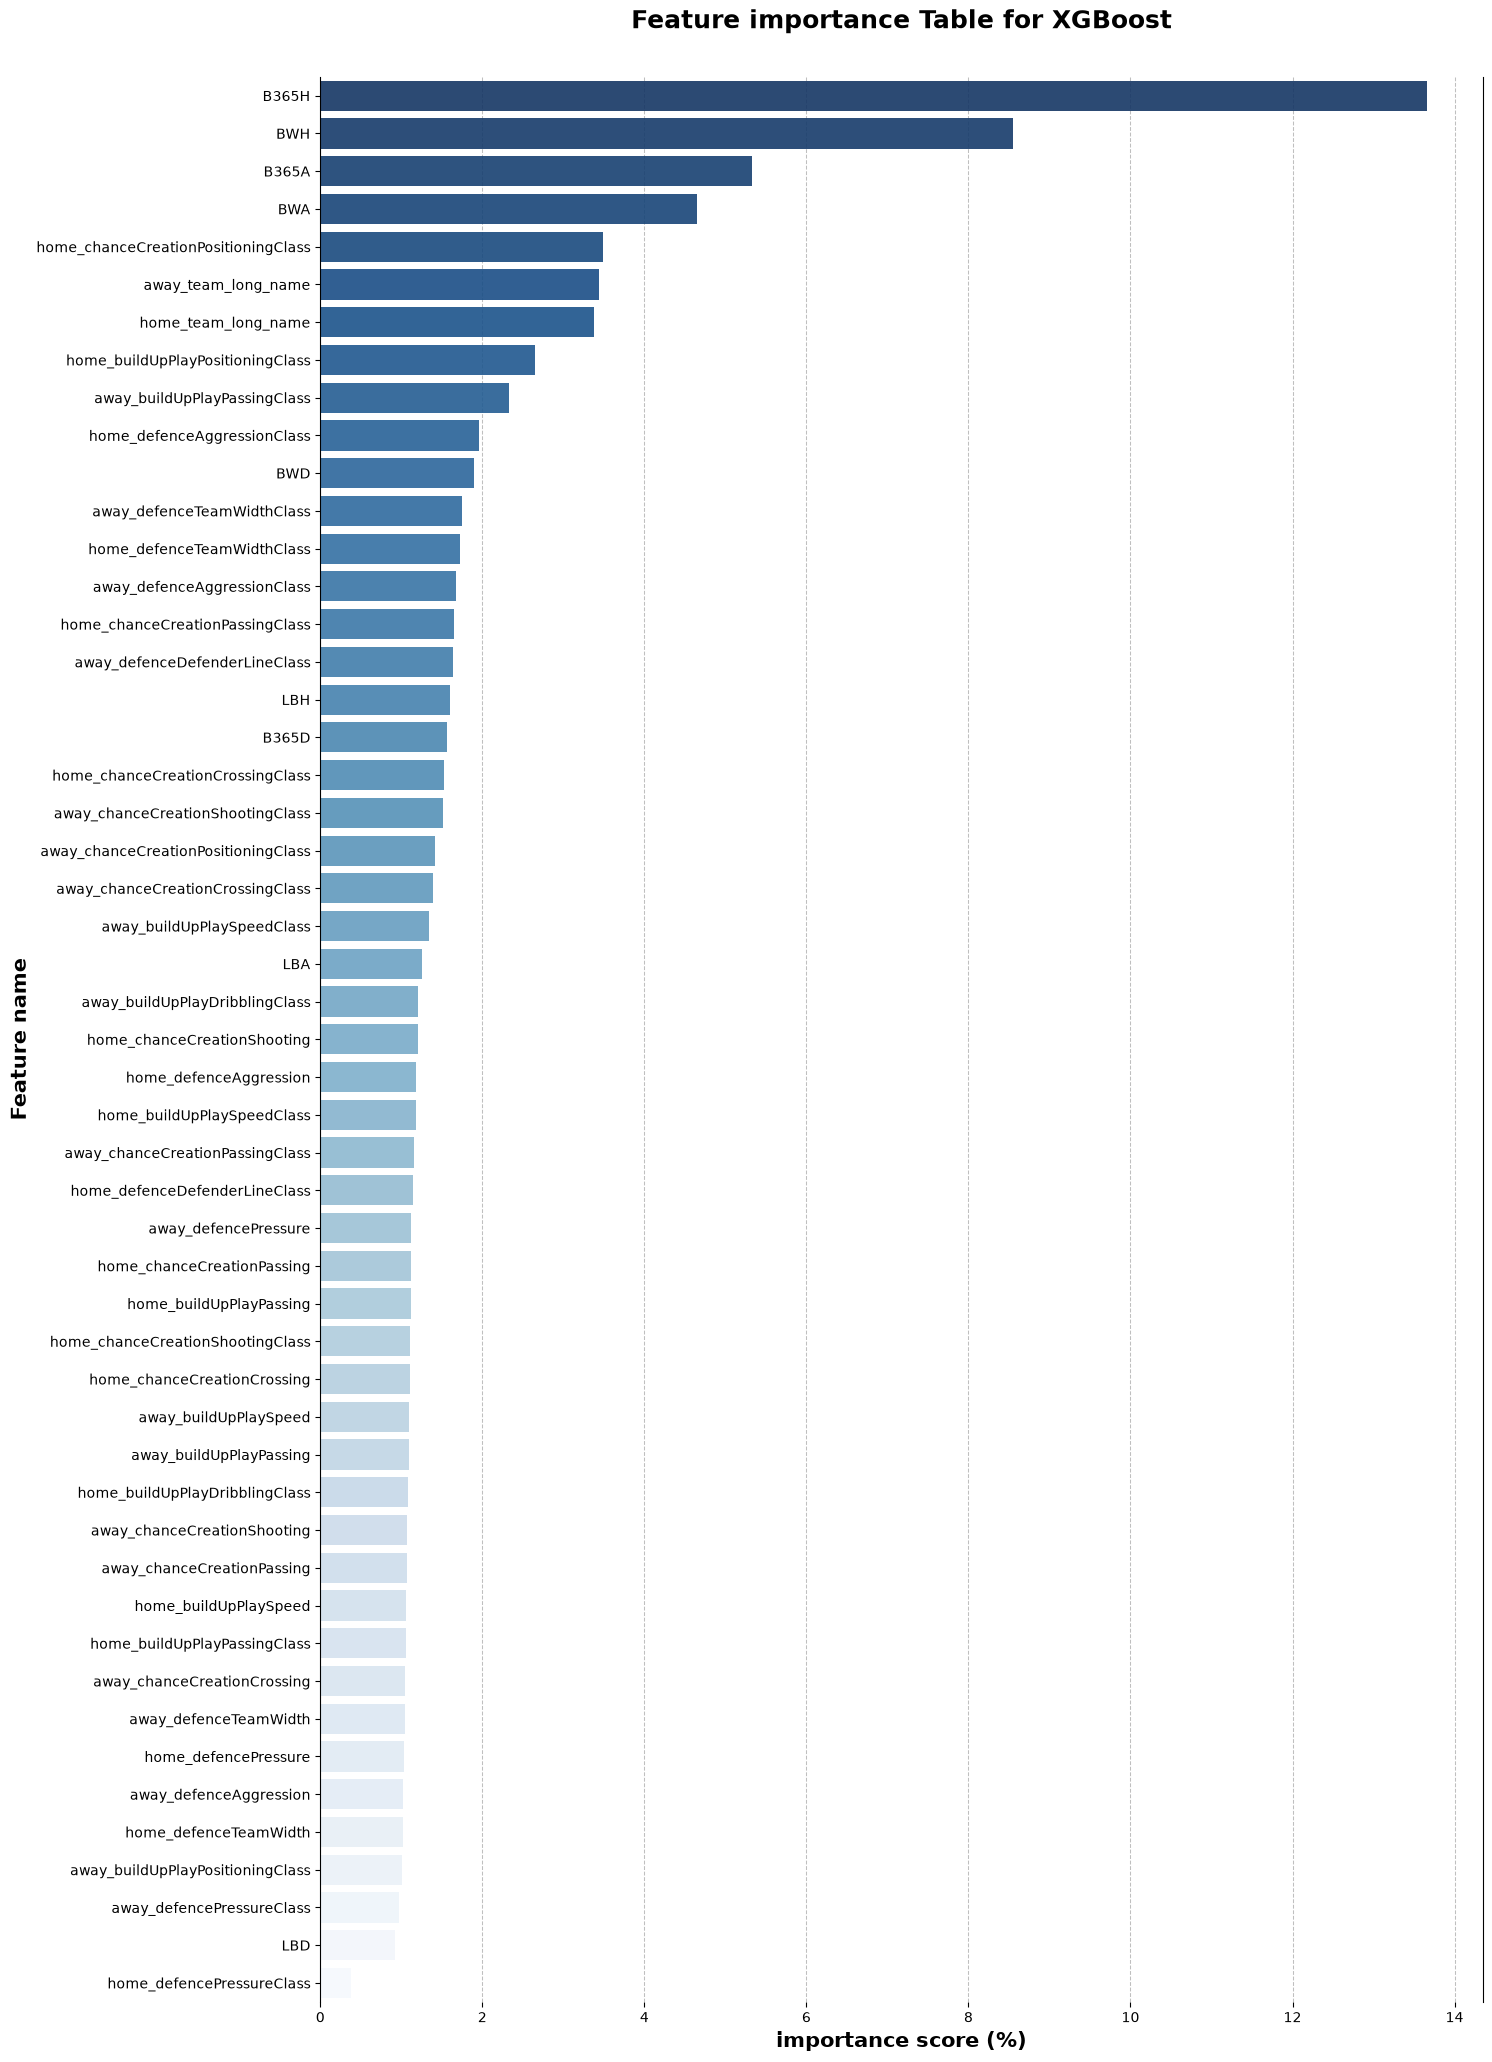

In [ ]:
plt.figure(figsize=(15,25))
ax = sns.barplot(data=XGBoost_feature_importance, x="importance", y='Columns', linewidth=1.5, alpha=0.9, hue="Columns", palette="Blues_r")
ax.set_title("Feature importance Table for XGBoost", fontsize=18, fontweight='bold' ,pad=35)
ax.set_xlabel("importance score (%)", fontsize=15,fontweight='bold')
ax.set_ylabel("Feature name", fontsize=15, fontweight='bold')
ax.set_axisbelow(True)
ax.grid(axis="x", linestyle='--', linewidth=0.75, alpha=0.8)
ax.spines["top"].set_visible(False)
ax.spines["bottom"].set_visible(False)
plt.show()

### Evaluation
Bookmaker odds, particularly B365H and BWH, dominate feature importance, followed by selected team identities and tactical attributes. However, given the model's weak test performance, these rankings do not establish the actual predictive value of individual features. Further investigation and comparison with CatBoost will help guide feature selection for Dataset V2.

---

## Experiment 4: CatBoost Classification

### Purpose
This experiment evaluates CatBoost on Dataset V1 to compare its performance against XGBoost. CatBoost supports numerical missing values and handles categorical features internally, allowing us to test a different boosting algorithm without manual categorical encoding.

In [91]:
from catboost import CatBoostClassifier

In [92]:
cat_cols = data_v1.select_dtypes(include=["category", "object"]).columns.tolist()

C:\Users\Admin\AppData\Local\Temp\ipykernel_13128\1815373230.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = data_v1.select_dtypes(include=["category", "object"]).columns.tolist()


In [93]:
cat_cols.remove("FTR")

In [39]:
cbc_model_1 = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, l2_leaf_reg=3, loss_function="MultiClass", random_seed=1, verbose=False, cat_features=cat_cols)

In [12]:
# Create copies
x_train_cat = x_train.copy()
x_test_cat = x_test.copy()

# Replace missing categorical values
for col in cat_cols:
    x_train_cat[col] = x_train_cat[col].astype("object").fillna("Missing")
    x_test_cat[col] = x_test_cat[col].astype("object").fillna("Missing")

In [42]:
cbc_model_1.fit(x_train_cat, y_train, cat_features=cat_cols)

CatBoostClassifier(cat_features=['home_team_long_name', 'away_team_long_name', 'home_buildUpPlaySpeedClass', 'home_buildUpPlayDribblingClass', 'home_buildUpPlayPassingClass', 'home_buildUpPlayPositioningClass', 'home_chanceCreationPassingClass', 'home_chanceCreationCrossingClass', 'home_chanceCreationShootingClass', 'home_chanceCreationPositioningClass', 'home_defencePressureClass', 'home_defenceAggressionClass', 'home_defenceTeamWidthClass', 'home_defenceDefenderLineClass', 'away_buildUpPlaySpeedClass', 'away_buildUpPlayDribblingClass', 'away_buildUpPlayPassingClass', 'away_buildUpPlayPositioningClass', 'away_chanceCreationPassingClass', 'away_chanceCreationCrossingClass', 'away_chanceCreationShootingClass', 'away_chanceCreationPositioningClass', 'away_defencePressureClass', 'away_defenceAggressionClass', 'away_defenceTeamWidthClass', 'away_defenceDefenderLineClass'], depth=6, iterations=200, l2_leaf_reg=3, learning_rate=0.1, loss_function='MultiClass', random_seed=1, verbose=False)

In [43]:
y_hat = cbc_model_1.predict(x_test_cat)
y_hat_train = cbc_model_1.predict(x_train_cat)

Evaluation

In [44]:
print(f"Accuracy of the model is {accuracy_score(y_test, y_hat)}")
print(f"Train Accuracy of the model is {accuracy_score(y_train, y_hat_train)}")

Accuracy of the model is 0.5239928149858866
Train Accuracy of the model is 0.5309870772614792


In [45]:
print("classification_report")
print(classification_report(y_test, y_hat))

classification_report
              precision    recall  f1-score   support

           0       0.49      0.44      0.46      2248
           1       0.27      0.00      0.01      1921
           2       0.54      0.85      0.66      3625

    accuracy                           0.52      7794
   macro avg       0.43      0.43      0.38      7794
weighted avg       0.46      0.52      0.44      7794



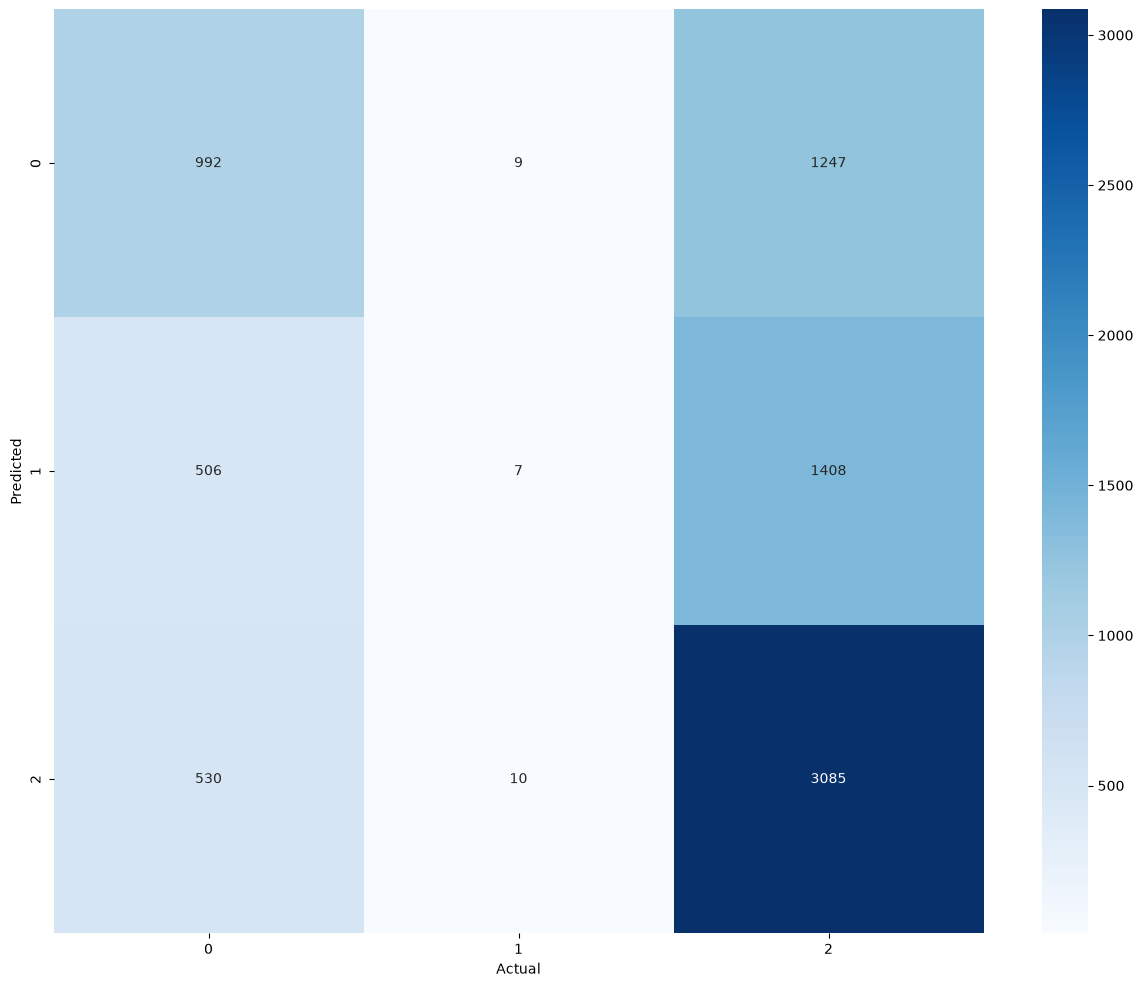

In [47]:
plt.figure(figsize=(15,12))
cm = confusion_matrix(y_test, y_hat)
sns.heatmap(cm, annot=True, fmt="d", cmap=("Blues"))
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

In [51]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Football_match_prediction")

with mlflow.start_run(run_name="Catboost experiment 3"):
    mlflow.log_input(dataset_v1, context="source")
    mlflow.log_params(cbc_model_1.get_params())

    mlflow.log_metrics({
    "train_accuracy":  0.531,
    "test_accuracy": 0.523,

    "precision_away": 0.49,
    "recall_away": 0.44,

    "precision_draw": 0.27,
    "recall_draw": 0.00,

    "precision_home": 0.54,
    "recall_home": 0.85
}
)

    mlflow.catboost.log_model(cbc_model_1, "Catboost Model 1")

2026/10/19 14:38:20 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run Catboost experiment 3 at: http://127.0.0.1:5000/#/experiments/1/runs/b3fbac46e70040ddbb031b0ed2c67507
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


### Experiment 4: CatBoost Evaluation

CatBoost achieved **52.40% test accuracy** and 53.10% training accuracy, outperforming XGBoost with minimal overfitting. However, Draw (Class 1) recall dropped to nearly 0%, while Home Win recall reached 85%. Despite improved accuracy, the model heavily favours home wins and struggles with balanced classification. Further experimentation is needed.

---

## Experiment 5: CatBoost — Learning Rate Tuning

### Purpose
This experiment evaluates different learning rates (0.01, 0.1, 0.5, and 1.0) to investigate their impact on model accuracy, generalization, and class-wise recall.

In [62]:
cbc_model_2 = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.5, l2_leaf_reg=3, loss_function="MultiClass", random_seed=1, verbose=False, cat_features=cat_cols)

In [63]:
cbc_model_2.fit(x_train_cat, y_train, cat_features=cat_cols)

CatBoostClassifier(cat_features=['home_team_long_name', 'away_team_long_name', 'home_buildUpPlaySpeedClass', 'home_buildUpPlayDribblingClass', 'home_buildUpPlayPassingClass', 'home_buildUpPlayPositioningClass', 'home_chanceCreationPassingClass', 'home_chanceCreationCrossingClass', 'home_chanceCreationShootingClass', 'home_chanceCreationPositioningClass', 'home_defencePressureClass', 'home_defenceAggressionClass', 'home_defenceTeamWidthClass', 'home_defenceDefenderLineClass', 'away_buildUpPlaySpeedClass', 'away_buildUpPlayDribblingClass', 'away_buildUpPlayPassingClass', 'away_buildUpPlayPositioningClass', 'away_chanceCreationPassingClass', 'away_chanceCreationCrossingClass', 'away_chanceCreationShootingClass', 'away_chanceCreationPositioningClass', 'away_defencePressureClass', 'away_defenceAggressionClass', 'away_defenceTeamWidthClass', 'away_defenceDefenderLineClass'], depth=6, iterations=200, l2_leaf_reg=3, learning_rate=0.5, loss_function='MultiClass', random_seed=1, verbose=False)

In [64]:
y_hat = cbc_model_2.predict(x_test_cat)
y_hat_train = cbc_model_2.predict(x_train_cat)

Evaluation

In [65]:
print(f"Accuracy of the model is {accuracy_score(y_test, y_hat)}")
print(f"Train Accuracy of the model is {accuracy_score(y_train, y_hat_train)}")

Accuracy of the model is 0.5023094688221709
Train Accuracy of the model is 0.5709650811108056


In [66]:
print("classification_report")
print(classification_report(y_test, y_hat))

classification_report
              precision    recall  f1-score   support

           0       0.47      0.41      0.43      2248
           1       0.30      0.11      0.16      1921
           2       0.54      0.77      0.64      3625

    accuracy                           0.50      7794
   macro avg       0.44      0.43      0.41      7794
weighted avg       0.46      0.50      0.46      7794



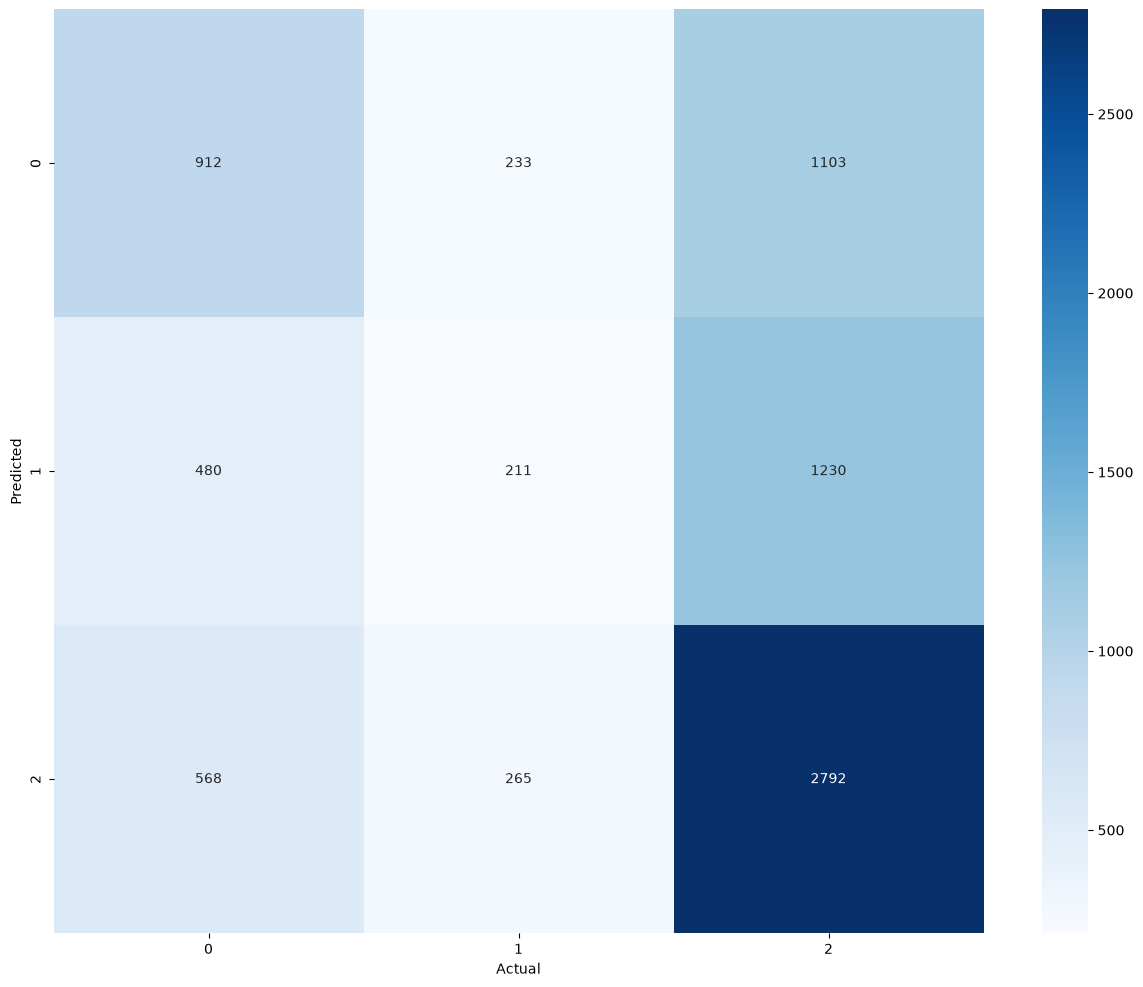

In [67]:
plt.figure(figsize=(15,12))
cm = confusion_matrix(y_test, y_hat)
sns.heatmap(cm, annot=True, fmt="d", cmap=("Blues"))
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

In [68]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Football_match_prediction")

with mlflow.start_run(run_name="Catboost experiment 2"):
    mlflow.log_input(dataset_v1, context="source")
    mlflow.log_params(cbc_model_2.get_params())

    mlflow.log_metrics({
    "train_accuracy": 0.571,
    "test_accuracy": 0.502,

    "precision_away": 0.47,
    "recall_away": 0.41,

    "precision_draw": 0.30,
    "recall_draw": 0.11,

    "precision_home": 0.54,
    "recall_home": 0.77
}
)

    mlflow.catboost.log_model(cbc_model_2, "Catboost Model 2")

2026/10/19 18:40:06 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run Catboost experiment 2 at: http://127.0.0.1:5000/#/experiments/1/runs/0b6c8cf2485d4421bbc6586f9d23f439
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


### Conclusion
A learning rate of **0.5** was selected as the preferred configuration, achieving **50.23% test accuracy** with a more balanced recall distribution across classes (Away: 41%, Draw: 11%, Home: 77%). Although lower learning rates achieved higher overall accuracy, they failed to identify draws. Therefore, 0.5 offers a better compromise between accuracy and class-wise recall, though draw prediction remains weak.

---

## Experiment 6: CatBoost — Balanced Class Weights

### Purpose

This experiment introduces auto_class_weights="Balanced" to address poor Draw (Class 1) recall. The objective is to improve class-wise recall by giving minority classes greater influence during training while evaluating the impact on overall accuracy.

In [78]:
cbc_model_3 = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.5, l2_leaf_reg=3, loss_function="MultiClass", random_seed=1, verbose=False, cat_features=cat_cols, auto_class_weights="Balanced")

In [79]:
cbc_model_3.fit(x_train_cat, y_train, cat_features=cat_cols)

CatBoostClassifier(auto_class_weights='Balanced', cat_features=['home_team_long_name', 'away_team_long_name', 'home_buildUpPlaySpeedClass', 'home_buildUpPlayDribblingClass', 'home_buildUpPlayPassingClass', 'home_buildUpPlayPositioningClass', 'home_chanceCreationPassingClass', 'home_chanceCreationCrossingClass', 'home_chanceCreationShootingClass', 'home_chanceCreationPositioningClass', 'home_defencePressureClass', 'home_defenceAggressionClass', 'home_defenceTeamWidthClass', 'home_defenceDefenderLineClass', 'away_buildUpPlaySpeedClass', 'away_buildUpPlayDribblingClass', 'away_buildUpPlayPassingClass', 'away_buildUpPlayPositioningClass', 'away_chanceCreationPassingClass', 'away_chanceCreationCrossingClass', 'away_chanceCreationShootingClass', 'away_chanceCreationPositioningClass', 'away_defencePressureClass', 'away_defenceAggressionClass', 'away_defenceTeamWidthClass', 'away_defenceDefenderLineClass'], depth=6, iterations=200, l2_leaf_reg=3, learning_rate=0.5, loss_function='MultiClass', 

In [80]:
y_hat = cbc_model_3.predict(x_test_cat)
y_hat_train = cbc_model_3.predict(x_train_cat)

Evaluation

In [81]:
print(f"Accuracy of the model is {accuracy_score(y_test, y_hat)}")
print(f"Train Accuracy of the model is {accuracy_score(y_train, y_hat_train)}")

Accuracy of the model is 0.45971259943546317
Train Accuracy of the model is 0.5577673907066263


In [82]:
print("classification_report")
print(classification_report(y_test, y_hat))

classification_report
              precision    recall  f1-score   support

           0       0.43      0.47      0.45      2248
           1       0.28      0.31      0.30      1921
           2       0.60      0.53      0.56      3625

    accuracy                           0.46      7794
   macro avg       0.44      0.44      0.44      7794
weighted avg       0.47      0.46      0.46      7794



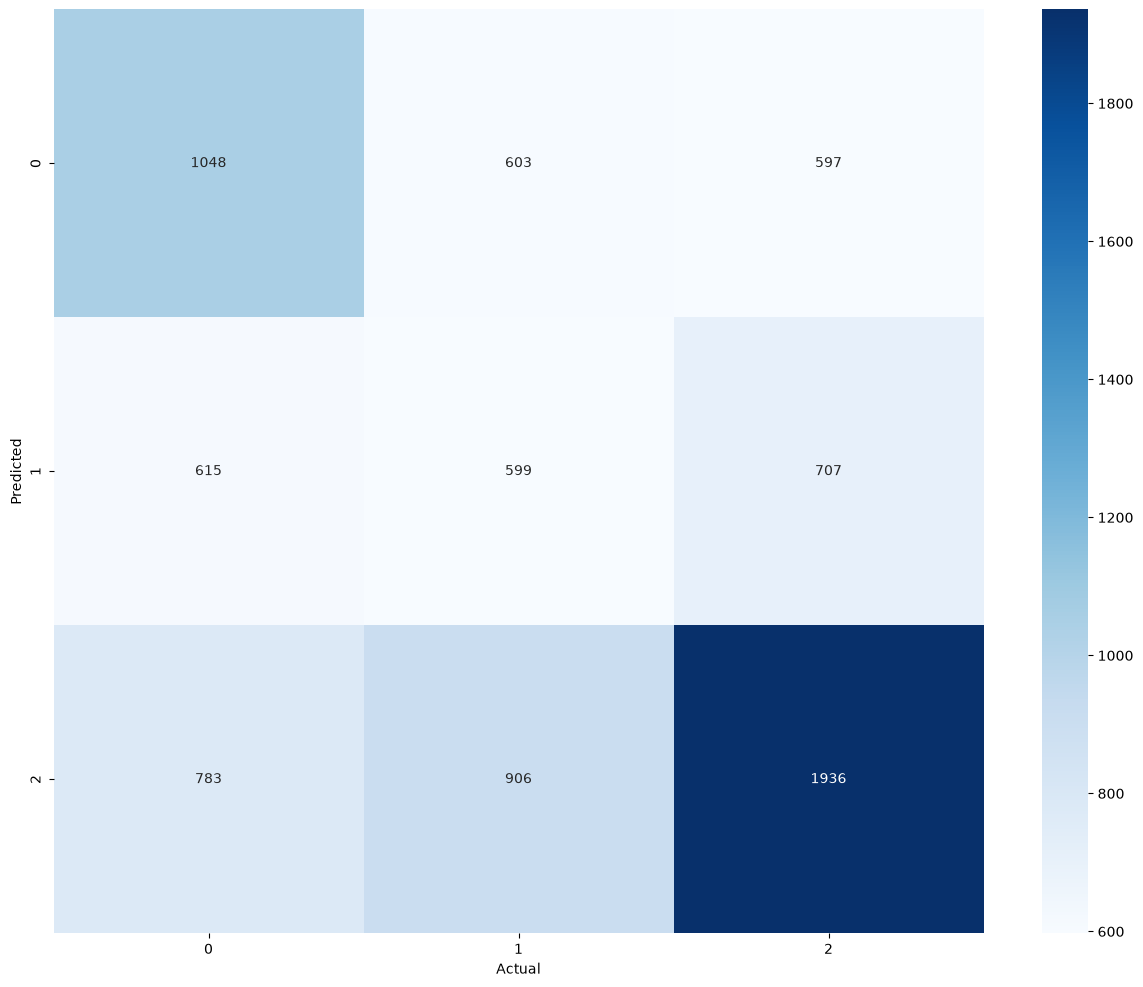

In [83]:
plt.figure(figsize=(15,12))
cm = confusion_matrix(y_test, y_hat)
sns.heatmap(cm, annot=True, fmt="d", cmap=("Blues"))
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

In [84]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Football_match_prediction")

with mlflow.start_run(run_name="Catboost experiment 3"):
    mlflow.log_input(dataset_v1, context="source")
    mlflow.log_params(cbc_model_3.get_params())

    mlflow.log_metrics({
    "train_accuracy": 0.56,
    "test_accuracy": 0.46,

    "precision_away": 0.43,
    "recall_away": 0.47,

    "precision_draw": 0.28,
    "recall_draw": 0.31,

    "precision_home": 0.60,
    "recall_home": 0.53
}
)

    mlflow.catboost.log_model(cbc_model_3, "Catboost Model 3")

2026/10/21 16:32:46 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run Catboost experiment 3 at: http://127.0.0.1:5000/#/experiments/1/runs/9df383f7425b426286e6d3d22feac014
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


### Experiment 6: Evaluation

This CatBoost configuration achieved **45.97% test accuracy** and **55.78% training accuracy**, showing a relatively small overfitting gap. Although overall accuracy declined, the model delivered the most balanced class-wise recall so far, particularly improving Draw recall to 31%. Therefore, this configuration is selected as our **balanced-performance benchmark** for further experimentation.

---

## Experiment 7: CatBoost — SqrtBalanced Class Weights

### Purpose
This experiment tests `auto_class_weights="SqrtBalanced"`, which applies less aggressive class weighting than `Balanced`. The objective is to recover some overall accuracy while maintaining improved Draw recall and a more balanced performance across all three classes.

In [94]:
cbc_model_4 = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.5, l2_leaf_reg=3, loss_function="MultiClass", random_seed=1, verbose=False, cat_features=cat_cols, auto_class_weights="SqrtBalanced")

In [95]:
cbc_model_4.fit(x_train_cat, y_train)

CatBoostClassifier(auto_class_weights='SqrtBalanced', cat_features=['home_team_long_name', 'away_team_long_name', 'home_buildUpPlaySpeedClass', 'home_buildUpPlayDribblingClass', 'home_buildUpPlayPassingClass', 'home_buildUpPlayPositioningClass', 'home_chanceCreationPassingClass', 'home_chanceCreationCrossingClass', 'home_chanceCreationShootingClass', 'home_chanceCreationPositioningClass', 'home_defencePressureClass', 'home_defenceAggressionClass', 'home_defenceTeamWidthClass', 'home_defenceDefenderLineClass', 'away_buildUpPlaySpeedClass', 'away_buildUpPlayDribblingClass', 'away_buildUpPlayPassingClass', 'away_buildUpPlayPositioningClass', 'away_chanceCreationPassingClass', 'away_chanceCreationCrossingClass', 'away_chanceCreationShootingClass', 'away_chanceCreationPositioningClass', 'away_defencePressureClass', 'away_defenceAggressionClass', 'away_defenceTeamWidthClass', 'away_defenceDefenderLineClass'], depth=6, iterations=200, l2_leaf_reg=3, learning_rate=0.5, loss_function='MultiClas

In [96]:
y_hat = cbc_model_4.predict(x_test_cat)
y_hat_train = cbc_model_4.predict(x_train_cat)

Evaluation

In [97]:
print(f"Accuracy of the model is {accuracy_score(y_test, y_hat)}")
print(f"Train Accuracy of the model is {accuracy_score(y_train, y_hat_train)}")

Accuracy of the model is 0.48742622530151397
Train Accuracy of the model is 0.5773439648061589


In [98]:
print("classification_report")
print(classification_report(y_test, y_hat))

classification_report
              precision    recall  f1-score   support

           0       0.46      0.46      0.46      2248
           1       0.27      0.17      0.21      1921
           2       0.56      0.68      0.61      3625

    accuracy                           0.49      7794
   macro avg       0.43      0.43      0.43      7794
weighted avg       0.46      0.49      0.47      7794



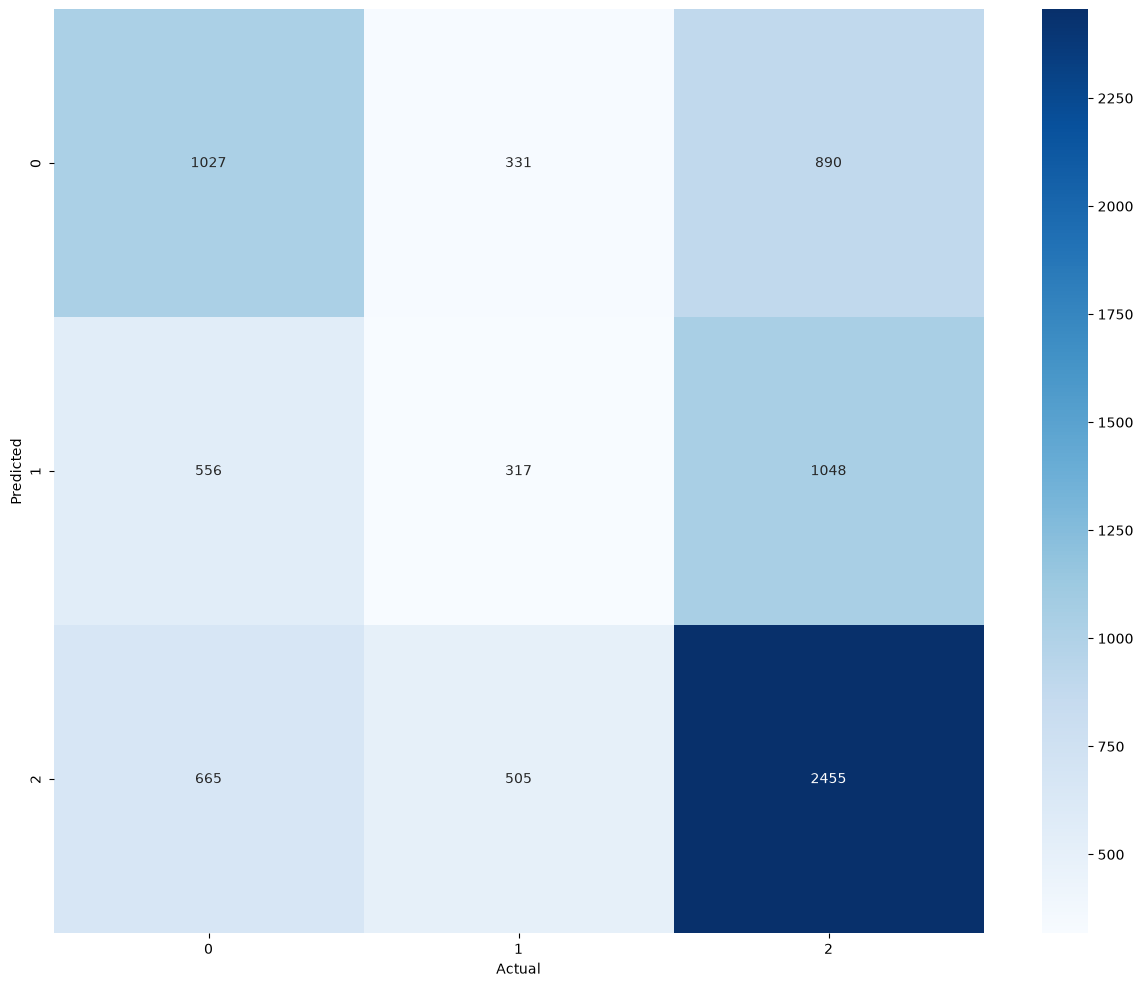

In [99]:
plt.figure(figsize=(15,12))
cm = confusion_matrix(y_test, y_hat)
sns.heatmap(cm, annot=True, fmt="d", cmap=("Blues"))
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

In [100]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Football_match_prediction")

with mlflow.start_run(run_name="Catboost experiment 4"):
    mlflow.log_input(dataset_v1, context="source")
    mlflow.log_params(cbc_model_4.get_params())

    mlflow.log_metrics({
    "train_accuracy": 0.58,
    "test_accuracy": 0.49,

    "precision_away": 0.46,
    "recall_away": 0.46,

    "precision_draw": 0.27,
    "recall_draw": 0.17,

    "precision_home": 0.56,
    "recall_home": 0.68
}
)

    mlflow.catboost.log_model(cbc_model_4, "Catboost Model 4")

2026/10/21 16:52:02 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run Catboost experiment 4 at: http://127.0.0.1:5000/#/experiments/1/runs/294d6d270eda46c1b0b69979cd26907b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


### Evaltion

Although `SqrtBalanced` improved test accuracy to **48.74%**, Draw recall declined from 31% to 17%. Experiment 6 (`Balanced`) remains the preferred configuration for its more balanced class-wise recall, despite lower overall accuracy. Further experiments will aim to improve accuracy without compromising minority-class performance.

---

## Experiment 8: CatBoost — Tree Depth Tuning

### Purpose
This experiment investigates the impact of tree depth (4, 5, 6, 7, and 8) on CatBoost's performance while keeping the remaining hyperparameters from Experiment 6 unchanged. The objective is to improve overall accuracy and generalization while maintaining balanced class-wise recall, particularly for Draw (Class 1).

In [137]:
cbc_model_5 = CatBoostClassifier(iterations=200, depth=4, learning_rate=0.5, l2_leaf_reg=3, loss_function="MultiClass", random_seed=1, verbose=False, cat_features=cat_cols, auto_class_weights="Balanced")

In [138]:
cbc_model_5.fit(x_train_cat, y_train)

CatBoostClassifier(auto_class_weights='Balanced', cat_features=['home_team_long_name', 'away_team_long_name', 'home_buildUpPlaySpeedClass', 'home_buildUpPlayDribblingClass', 'home_buildUpPlayPassingClass', 'home_buildUpPlayPositioningClass', 'home_chanceCreationPassingClass', 'home_chanceCreationCrossingClass', 'home_chanceCreationShootingClass', 'home_chanceCreationPositioningClass', 'home_defencePressureClass', 'home_defenceAggressionClass', 'home_defenceTeamWidthClass', 'home_defenceDefenderLineClass', 'away_buildUpPlaySpeedClass', 'away_buildUpPlayDribblingClass', 'away_buildUpPlayPassingClass', 'away_buildUpPlayPositioningClass', 'away_chanceCreationPassingClass', 'away_chanceCreationCrossingClass', 'away_chanceCreationShootingClass', 'away_chanceCreationPositioningClass', 'away_defencePressureClass', 'away_defenceAggressionClass', 'away_defenceTeamWidthClass', 'away_defenceDefenderLineClass'], depth=4, iterations=200, l2_leaf_reg=3, learning_rate=0.5, loss_function='MultiClass', 

In [139]:
y_hat = cbc_model_5.predict(x_test_cat)
y_hat_train = cbc_model_5.predict(x_train_cat)

#### Evlaution 

In [140]:
print(f"Accuracy of the model is {accuracy_score(y_test, y_hat)}")
print(f"Train Accuracy of the model is {accuracy_score(y_train, y_hat_train)}")

Accuracy of the model is 0.4606107261996408
Train Accuracy of the model is 0.5099807533681606


In [141]:
print("classification_report")
print(classification_report(y_test, y_hat))

classification_report
              precision    recall  f1-score   support

           0       0.44      0.50      0.47      2248
           1       0.28      0.35      0.31      1921
           2       0.63      0.50      0.55      3625

    accuracy                           0.46      7794
   macro avg       0.45      0.45      0.44      7794
weighted avg       0.49      0.46      0.47      7794



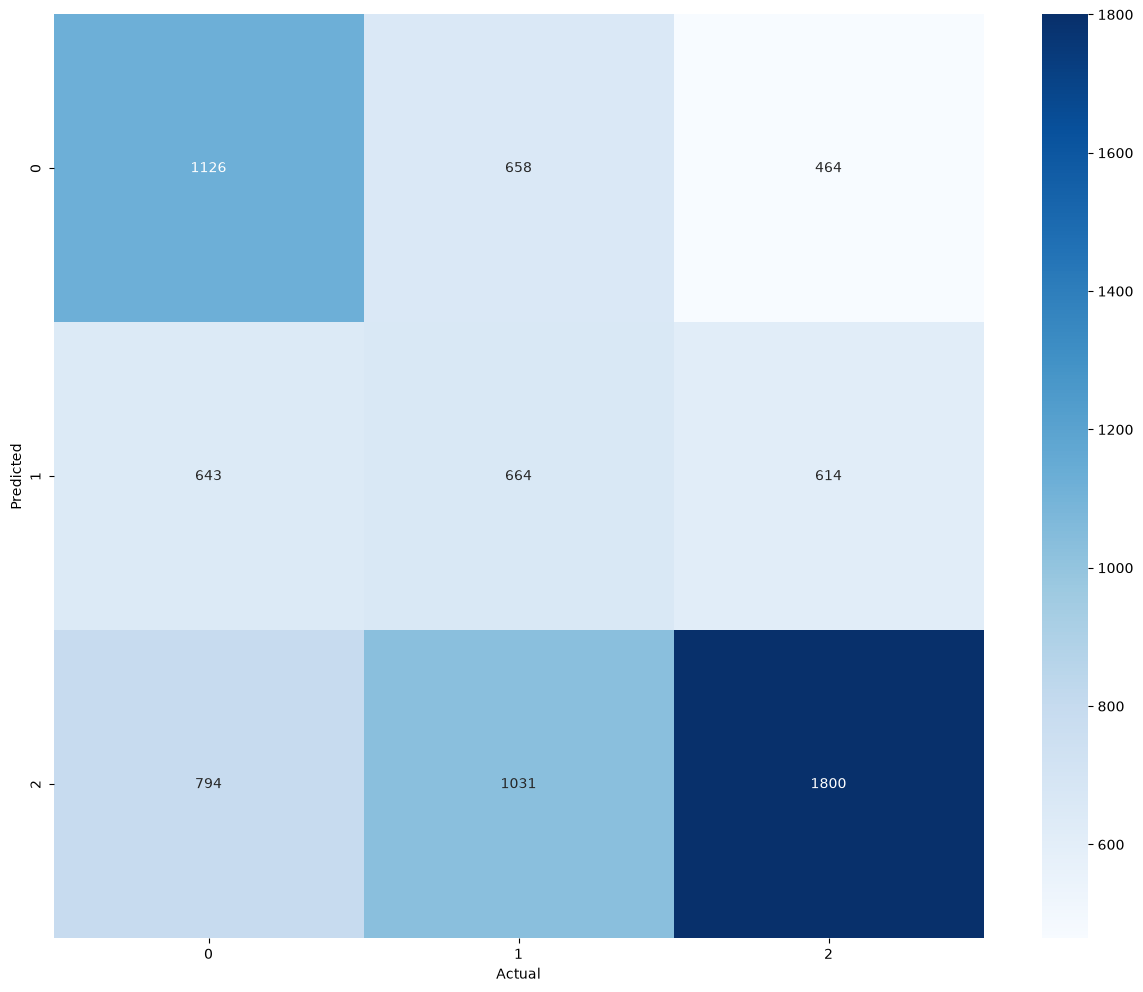

In [143]:
plt.figure(figsize=(15,12))
cm = confusion_matrix(y_test, y_hat)
sns.heatmap(cm, annot=True, fmt="d", cmap=("Blues"))
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

In [144]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Football_match_prediction")

with mlflow.start_run(run_name="Catboost experiment 5"):
    mlflow.log_input(dataset_v1, context="source")
    mlflow.log_params(cbc_model_5.get_params())

    mlflow.log_metrics({
    "train_accuracy": 0.51,
    "test_accuracy": 0.46,

    "precision_away": 0.44,
    "recall_away": 0.50,

    "precision_draw": 0.28,
    "recall_draw": 0.35,

    "precision_home": 0.63,
    "recall_home": 0.50
}
)

    mlflow.catboost.log_model(cbc_model_5, "Catboost Model 5")

2026/10/21 21:56:49 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run Catboost experiment 5 at: http://127.0.0.1:5000/#/experiments/1/runs/10b12d578fef494cb6a284b80842ba5b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


### Evaluation
Reducing CatBoost's tree depth to **4** produced the most balanced recall across all three classes, improving Draw recall to **35%**, the highest achieved so far. Although test accuracy remained relatively low at **46.06%**, the model showed limited overfitting. This configuration becomes our new balanced-performance benchmark. Further improvements will be explored through alternative preprocessing and modelling approaches.

---

## CatBoost Feature Importance Analysis

### Purpose
This section extracts and visualizes feature importance from the selected CatBoost model (`cbc_model_5`) to identify which variables contribute most to its predictions. The results will later be compared with XGBoost's feature importance to guide evidence-based feature selection for future dataset versions.

In [154]:
catboost_feature_importance = pd.DataFrame()

In [155]:
catboost_feature_importance["Columns"] = x.columns

In [160]:
catboost_feature_importance["Importance"] = cbc_model_5.get_feature_importance()

In [165]:
catboost_feature_importance = catboost_feature_importance.sort_values(by="Importance", ascending=False).reset_index(drop=True)

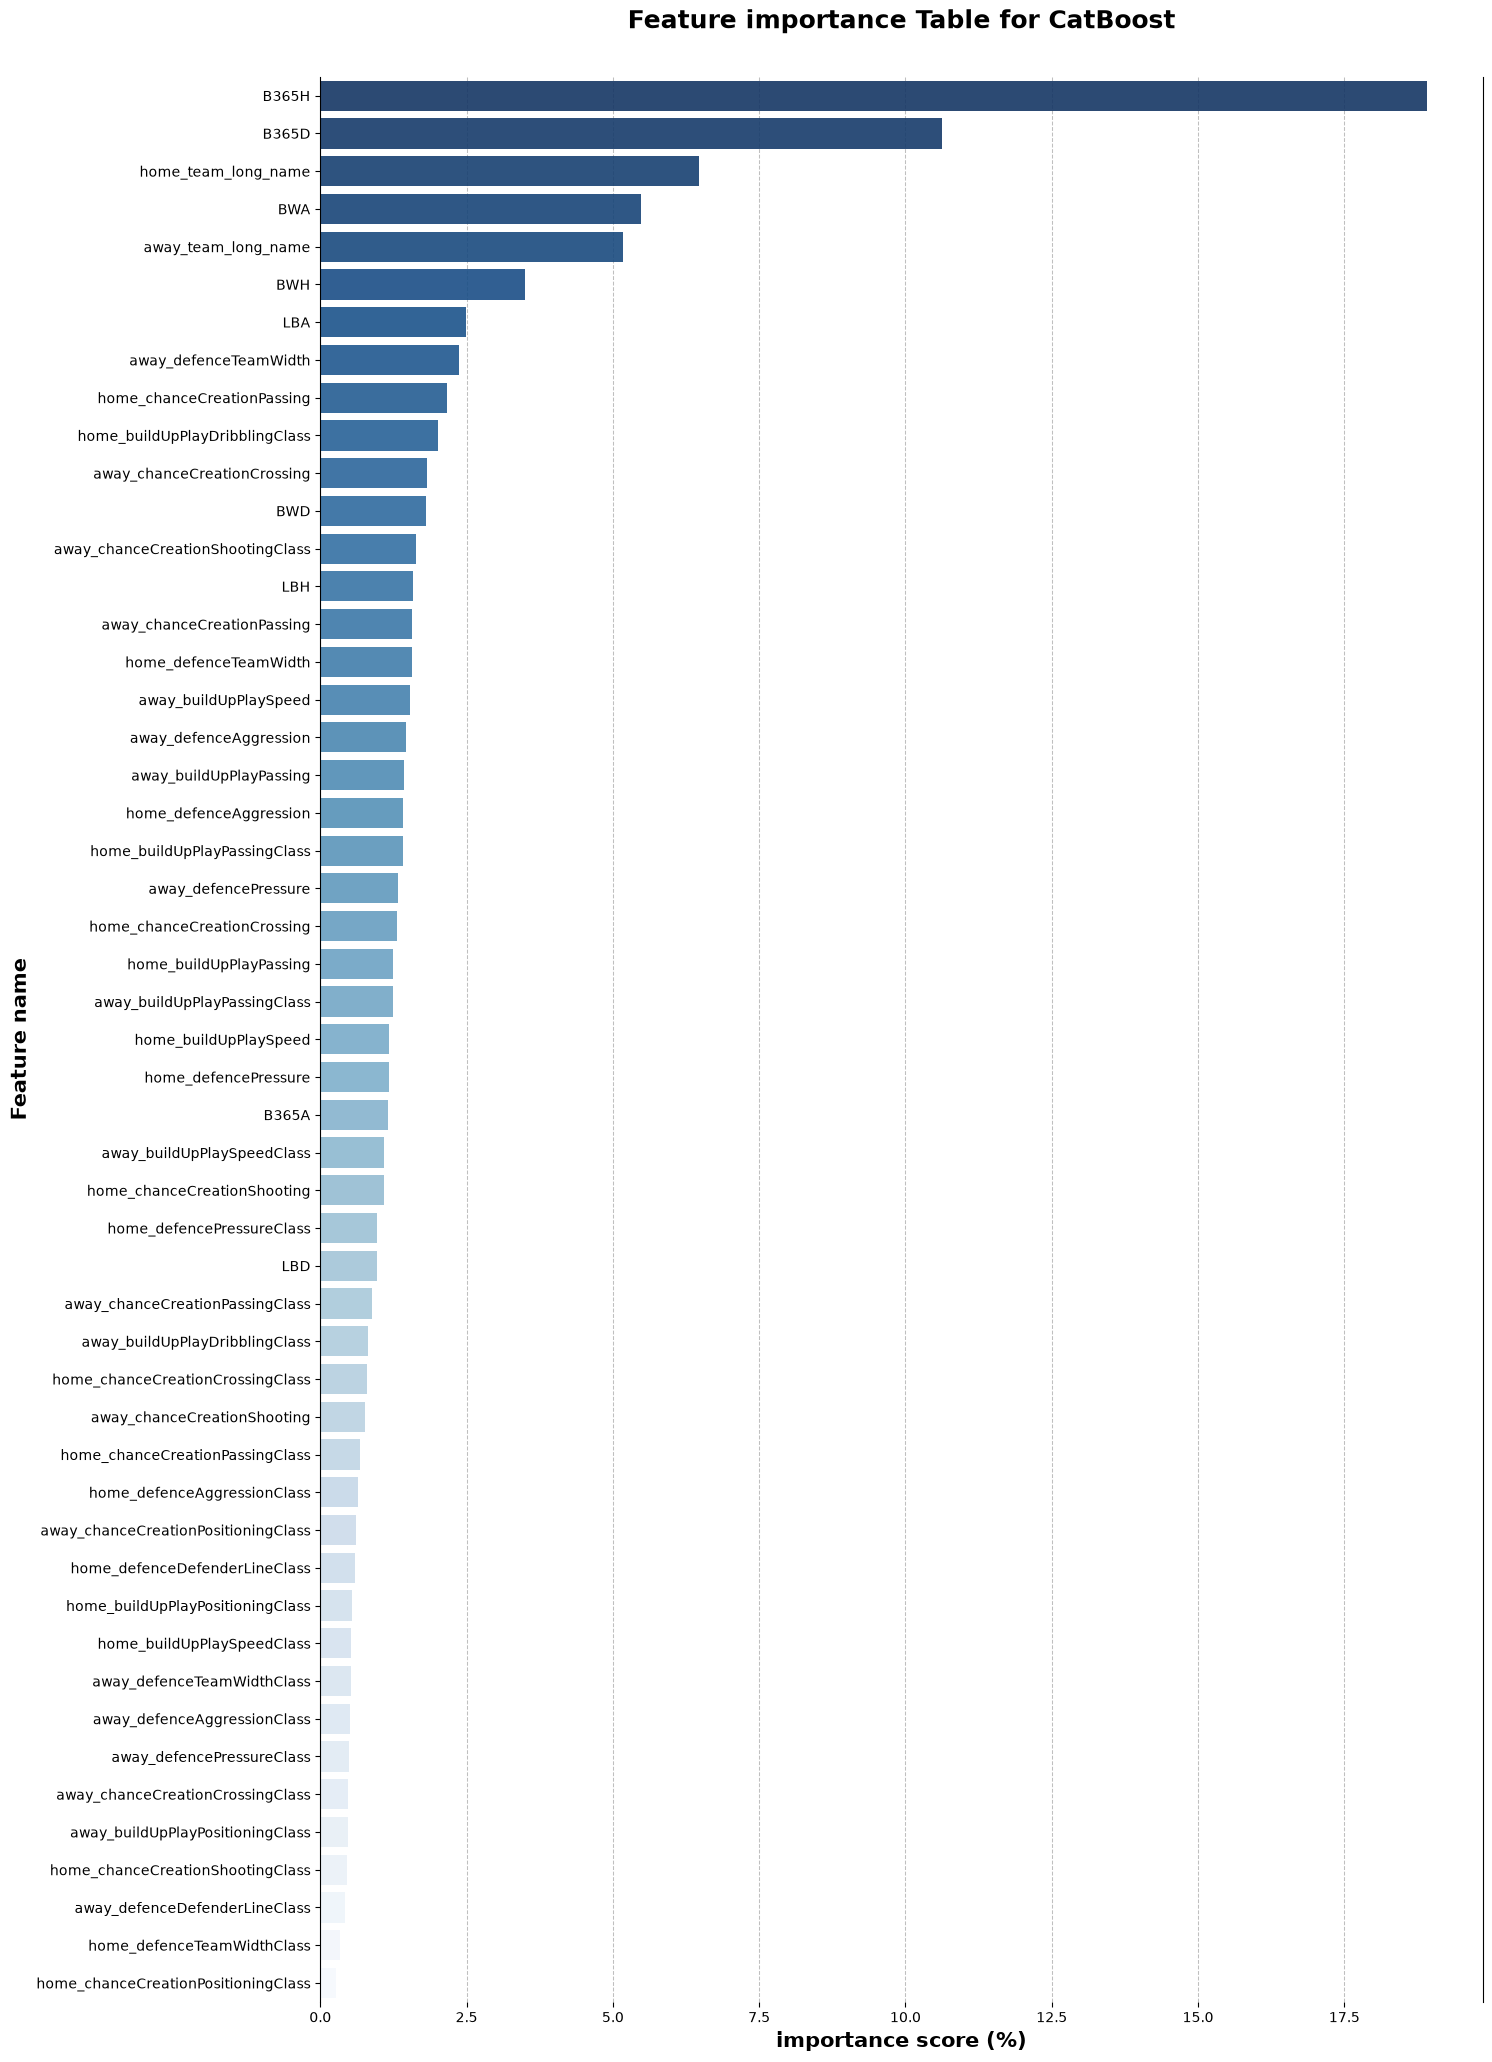

In [166]:
plt.figure(figsize=(15,25))
ax = sns.barplot(data=catboost_feature_importance, x="Importance", y='Columns', linewidth=1.5, alpha=0.9, hue="Columns", palette="Blues_r")
ax.set_title("Feature importance Table for CatBoost", fontsize=18, fontweight='bold' ,pad=35)
ax.set_xlabel("importance score (%)", fontsize=15,fontweight='bold')
ax.set_ylabel("Feature name", fontsize=15, fontweight='bold')
ax.set_axisbelow(True)
ax.grid(axis="x", linestyle='--', linewidth=0.75, alpha=0.8)
ax.spines["top"].set_visible(False)
ax.spines["bottom"].set_visible(False)
plt.show()

### CatBoost Feature Importance — Conclusion

The analysis shows that **bookmaker odds, particularly B365H and B365D, dominate feature importance**, followed by team identities and selected tactical attributes. Most tactical features contribute relatively little individually. These findings suggest that CatBoost relies heavily on bookmaker information, although feature importance alone cannot establish predictive value. The results will be compared with XGBoost before making feature-selection decisions for future dataset versions.

---

## Dataset V1.0 — Comparative Feature Importance Analysis

### Overview

Feature importance was extracted from the selected XGBoost and CatBoost models to investigate which features influence their predictions. The objective is to identify consistent patterns, understand differences between the algorithms, and guide feature experimentation in future dataset versions.

### 1. Key Findings

| Feature / Group | XGBoost | CatBoost | Observation |
|---|---|---|---|
| **B365H** | Highest importance | Highest importance | Strongest agreement between both models |
| **B365D** | Moderate importance | Second highest | Considerably more influential in CatBoost |
| **B365A** | Third highest | Relatively low | Considerably more influential in XGBoost |
| **BWH** | Second highest | Sixth highest | Important in both, particularly XGBoost |
| **BWA** | Fourth highest | Fourth highest | Consistently important across both |
| **Team names** | Among leading features | Among leading features | Both algorithms rely significantly on team identity |
| **Ladbrokes odds** | Generally lower importance | LBA shows moderate importance | Less consistently influential than Bet365 and Bet & Win |
| **Tactical attributes** | Selected categorical features rank highly | Selected numerical and categorical features contribute | Different tactical features are prioritised |

### 2. Bookmaker Odds

- **Bet365:** `B365H` ranks first in both models, making it the most consistently influential individual feature. However, `B365D` and `B365A` show substantial differences between algorithms.
- **Bet & Win:** `BWH` and `BWA` receive relatively high importance in XGBoost. Both remain relevant in CatBoost, particularly `BWA`.
- **Ladbrokes:** Most features receive relatively modest importance, although `LBA` ranks noticeably higher in CatBoost.

**Observation:** Both algorithms rely heavily on bookmaker odds, suggesting that market-derived information is important to their predictions. However, individual bookmaker features may contain overlapping information, so low importance does not necessarily indicate redundancy.

### 3. Team Identity

Both `home_team_long_name` and `away_team_long_name` rank among the more influential features in both algorithms.

- CatBoost assigns particularly high importance to both team identity features.
- XGBoost also identifies them as important, although bookmaker odds and selected tactical features receive greater emphasis.

**Observation:** Team identity appears to provide meaningful information to both models, potentially reflecting historical differences in team strength and performance. Its contribution should be tested further rather than assumed.

### 4. Team Tactical Attributes

The models show greater disagreement in their evaluation of tactical characteristics.

**XGBoost highlights:**
- `home_chanceCreationPositioningClass`
- `home_buildUpPlayPositioningClass`
- `away_buildUpPlayPassingClass`
- `home_defenceAggressionClass`

**CatBoost highlights:**
- `away_defenceTeamWidth`
- `home_chanceCreationPassing`
- `home_buildUpPlayDribblingClass`
- `away_chanceCreationCrossing`

Interestingly, `home_chanceCreationPositioningClass` ranks highly in XGBoost but has almost no importance in CatBoost.

**Observation:** Tactical features generally have lower individual importance than the leading bookmaker odds. However, the algorithms prioritise different tactical characteristics, suggesting that their contribution requires further investigation before feature removal.

### 5. Overall Conclusion and Implications for Future Experiments

The comparison reveals three main findings:

1. **Bookmaker odds are consistently influential**, especially `B365H`, although the relative importance of individual odds differs considerably between algorithms.
2. **Team identity remains important across both models**, making home and away team names strong candidates for retention.
3. **Tactical attributes show inconsistent importance**, with different numerical and categorical characteristics receiving emphasis depending on the algorithm.

Importantly, these are model-specific importance rankings, calculated using different methods. Their raw importance scores should not be directly compared or interpreted as proof of predictive usefulness.

### Direction for Dataset V1.2

The current findings do not justify permanently removing any feature group. Instead, future experiments should investigate whether alternative categorical encoding, missing-value handling, and classification algorithms improve performance.

Further experiments can also compare models **with and without bookmaker odds**, examine the contribution of tactical features, and evaluate whether correlated features provide additional predictive information.

**Final assessment:** Dataset V1.0 provides useful evidence about model reliance on features, but its predictive limitations remain unresolved. Feature-selection decisions should therefore be supported by further model experiments rather than importance rankings alone.

---

## Dataset V1.2 — Filtering Missing Team Identities

During Dataset V1.0 analysis, approximately 27.6% of home and away team-name entries were found to be missing.

Since team identity was identified as an influential predictor in both XGBoost and CatBoost, matches missing either team name have been excluded while retaining both features.

This experiment also investigates whether missing team identities are associated with missing tactical attributes, potentially originating from earlier data joins.

**Limitation:** The cause of missing team identities has not yet been confirmed. The original joins will be revisited before final model development if this dataset version is selected.

In [167]:
team_cols = ["home_team_long_name", "away_team_long_name"]

data_v1_2 = data_v1.dropna(subset=team_cols).copy()

In [168]:
print("Original matches:", len(data_v1))
print("Remaining matches:", len(data_v1_2))
print("Dropped matches:", len(data_v1) - len(data_v1_2))

Original matches: 25979
Remaining matches: 18243
Dropped matches: 7736


In [169]:
missing_comparison = pd.DataFrame({
    "V1.0 Missing": data_v1.isna().sum(),
    "V1_2 Missing": data_v1_2.isna().sum(),
    "V1.0 Missing %": data_v1.isna().mean() * 100,
    "V1_2 Missing %": data_v1_2.isna().mean() * 100
}).round(2)

missing_comparison

,V1.0 Missing,V1_2 Missing,V1.0 Missing %,V1_2 Missing %
home_team_long_name,7163,0,27.57,0.00
away_team_long_name,7165,0,27.58,0.00
home_buildUpPlaySpeed,7163,0,27.57,0.00
home_buildUpPlaySpeedClass,7163,0,27.57,0.00
home_buildUpPlayDribblingClass,7163,0,27.57,0.00
home_buildUpPlayPassing,7163,0,27.57,0.00
home_buildUpPlayPassingClass,7163,0,27.57,0.00
home_buildUpPlayPositioningClass,7163,0,27.57,0.00
home_chanceCreationPassing,7163,0,27.57,0.00
home_chanceCreationPassingClass,7163,0,27.57,0.00


In [170]:
data_v1_2.head()

,home_team_long_name,away_team_long_name,home_buildUpPlaySpeed,home_buildUpPlaySpeedClass,home_buildUpPlayDribblingClass,home_buildUpPlayPassing,home_buildUpPlayPassingClass,home_buildUpPlayPositioningClass,home_chanceCreationPassing,home_chanceCreationPassingClass,...,B365H,B365D,B365A,BWH,BWD,BWA,LBH,LBD,LBA,FTR
376,RSC Anderlecht,Club Brugge KV,50.0,Balanced,Little,35.0,Mixed,Organised,70.0,Risky,...,1.73,3.60,4.75,1.75,3.40,4.25,1.66,3.4,4.33,H
378,Sporting Charleroi,Standard de Liège,40.0,Balanced,Little,50.0,Mixed,Organised,45.0,Normal,...,3.50,3.30,2.10,3.45,3.20,2.00,3.20,3.2,2.00,A
381,KV Mechelen,Beerschot AC,65.0,Balanced,Little,60.0,Mixed,Organised,50.0,Normal,...,2.40,3.25,2.90,2.35,3.15,2.80,2.30,3.3,2.60,H
404,Club Brugge KV,KVC Westerlo,35.0,Balanced,Little,40.0,Mixed,Organised,45.0,Normal,...,1.44,4.50,7.00,1.35,4.40,7.50,1.33,4.0,8.00,H
405,Standard de Liège,RSC Anderlecht,53.0,Balanced,Little,40.0,Mixed,Organised,55.0,Normal,...,3.00,3.25,2.38,2.75,3.10,2.40,2.60,3.2,2.37,A


In [174]:
cat_cols = data_v1_2.select_dtypes(include=("object","str"))
cat_cols.nunique()

home_team_long_name                    277
away_team_long_name                    277
home_buildUpPlaySpeedClass               3
home_buildUpPlayDribblingClass           3
home_buildUpPlayPassingClass             3
home_buildUpPlayPositioningClass         2
home_chanceCreationPassingClass          3
home_chanceCreationCrossingClass         3
home_chanceCreationShootingClass         3
home_chanceCreationPositioningClass      2
home_defencePressureClass                3
home_defenceAggressionClass              3
home_defenceTeamWidthClass               3
home_defenceDefenderLineClass            2
away_buildUpPlaySpeedClass               3
away_buildUpPlayDribblingClass           3
away_buildUpPlayPassingClass             3
away_buildUpPlayPositioningClass         2
away_chanceCreationPassingClass          3
away_chanceCreationCrossingClass         3
away_chanceCreationShootingClass         3
away_chanceCreationPositioningClass      2
away_defencePressureClass                3
away_defenc

In [177]:
data_v1_2.describe().T

,count,mean,std,min,25%,50%,75%,max
home_buildUpPlaySpeed,18243.0,52.675,11.897,20.00,45.00,53.0,63.00,80.0
home_buildUpPlayPassing,18243.0,47.862,11.144,20.00,39.00,49.0,55.00,80.0
home_chanceCreationPassing,18243.0,52.477,10.497,21.00,47.00,52.0,60.00,80.0
home_chanceCreationCrossing,18243.0,54.076,11.192,20.00,48.00,53.0,63.00,80.0
home_chanceCreationShooting,18243.0,54.259,10.600,22.00,49.00,54.0,63.00,80.0
home_defencePressure,18243.0,46.483,10.329,23.00,39.00,46.0,53.00,72.0
home_defenceAggression,18243.0,49.598,9.998,24.00,44.00,48.0,56.00,72.0
home_defenceTeamWidth,18243.0,52.276,9.552,29.00,48.00,52.0,59.00,73.0
away_buildUpPlaySpeed,18243.0,52.662,11.875,20.00,45.00,53.0,63.00,80.0
away_buildUpPlayPassing,18243.0,47.867,11.135,20.00,39.00,49.0,55.00,80.0


In [180]:
bookmakers = {
    "Bet365": ["B365H", "B365D", "B365A"],
    "BetWin": ["BWH", "BWD", "BWA"],
    "Ladbrokes": ["LBH", "LBD", "LBA"]
}

missing_pattern = pd.DataFrame({
    name: data_v1_2[cols].isna().all(axis=1)
    for name, cols in bookmakers.items()
})

display(missing_pattern.value_counts())

Bet365  BetWin  Ladbrokes
False   False   False        16043
True    True    True          2151
False   False   True            30
        True    False           15
                True             2
True    False   False            2
Name: count, dtype: int64

In [181]:
odds_cols = [
    "B365H", "B365D", "B365A",
    "BWH", "BWD", "BWA",
    "LBH", "LBD", "LBA"
]

data_v1_2 = data_v1_2.dropna(subset=odds_cols).copy()

print("Remaining matches:", data_v1_2.shape[0])
print("Total missing values:", data_v1_2.isna().sum().sum())

Remaining matches: 16043
Total missing values: 0


In [183]:
data_v1_2["FTR"].value_counts()

FTR
H    7372
A    4604
D    4067
Name: count, dtype: int64

In [184]:
dataset_v1_2 = mlflow.data.from_pandas(
    data_v1_2,
    name="Dataset_v1.2",
    targets="FTR"
)

## Dataset V1.2 — Data Inspection and Preparation Summary

Dataset V1.2 was developed by refining Dataset V1.0, addressing missing team identities, tactical attributes, and bookmaker odds. The objective was to establish a complete experimental dataset for alternative classification approaches.

### 1. Dataset Cleaning Results

- **Original Dataset V1.0:** 25,979 matches.
- **After removing missing team identities:** 18,243 matches.
- **After removing missing bookmaker odds:** 16,043 matches.
- **Total removed:** 9,936 matches (38.25%).
- **Team identities:** No remaining missing values.
- **Tactical attributes:** All 40 attributes have complete values.
- **Bookmaker odds:** All nine betting-odds features have complete values.

**Missing Team Identities and Tactical Attributes**

Removing matches with missing home or away team names also eliminated all missing values across the 40 tactical attributes. This confirmed a strong relationship between missing team identities and tactical information.

The underlying cause remains unconfirmed and will be revisited during final dataset preparation if necessary.

**Missing Bookmaker Odds**

Further inspection identified 2,200 matches with missing bookmaker information. Of these, **2,151 matches (97.8%) were missing odds from all three bookmakers simultaneously**, while only 49 had partial bookmaker coverage.

Since bookmaker odds received high feature-importance scores in both XGBoost and CatBoost, rows with incomplete bookmaker information were removed rather than introducing estimated odds through imputation.

This decision preserves complete observed bookmaker information for modelling, although it reduces the available sample size.

### 2. Final Target Class Distribution

| Match outcome | Matches | Percentage |
|---|---:|---:|
| Home win (H) | 7,372 | 45.95% |
| Away win (A) | 4,604 | 28.70% |
| Draw (D) | 4,067 | 25.35% |
| **Total** | **16,043** | **100%** |

The dataset continues to show moderate class imbalance, with home wins representing the largest class.

Importantly, the class proportions have remained almost unchanged following bookmaker-odds filtering. This indicates that the additional removal of matches has not materially altered the overall outcome distribution.

No class-balancing technique will be applied initially. Instead, class-specific recall and macro F1 will be monitored during model evaluation.

### 3. Planned Preprocessing

With all missing values addressed, the remaining preprocessing focuses on categorical encoding and numerical feature scaling.

- **Categorical features:** One-hot encoding for team identities and tactical categories.
- **Numerical tactical attributes:** Standardization where appropriate.
- **Bookmaker odds:** No imputation required; scaling according to model requirements.
- **Target:** Encode Away = 0, Draw = 1, Home = 2.

Model-specific preprocessing will be implemented through `ColumnTransformer` and sklearn pipelines.

### 4. Final Assessment

Dataset V1.2 now contains **16,043 complete match records with zero missing values**. The relationship between missing team identities and tactical attributes was identified, and incomplete bookmaker information was removed without introducing artificial odds values.

The final target distribution remains highly consistent with the earlier dataset, providing a stable class distribution for subsequent experiments.

However, the removal of approximately **38.25% of the original matches** remains an important limitation. Filtering may affect dataset representativeness even though the overall target distribution has remained stable.

Consequently, improvements over Dataset V1.0 cannot automatically be attributed to model selection or preprocessing alone.

**Next stage:** Begin categorical encoding, numerical scaling, and alternative classification experiments, starting with Logistic Regression using L1 and L2 regularization. Model performance will be evaluated using accuracy, macro F1, and class-specific recall.

---

## Train and Test spliting

In [190]:
X_v12 = data_v1_2.drop(columns=["FTR"]).copy()
y_v12 = data_v1_2["FTR"].map({"D": 0, "H": 1, "A": 2})

x_train, x_test, y_train, y_test = train_test_split(
    X_v12,
    y_v12,
    test_size=0.3,
    random_state=1
)

---

## Experiment 9 — CatBoost Performance Evaluation on Dataset V1.2

**Purpose:** Evaluate the selected CatBoost configuration from Experiment 8 on the cleaned Dataset V1.2, keeping hyperparameters unchanged to investigate how removing incomplete match records affects model performance.

In [191]:
cat_cols_v12 = data_v1_2.select_dtypes(include=["object", "category"]).columns.tolist()

C:\Users\Admin\AppData\Local\Temp\ipykernel_13128\2429305538.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols_v12 = data_v1_2.select_dtypes(include=["object", "category"]).columns.tolist()


In [192]:
cat_cols_v12.remove("FTR")

In [194]:
cbc_model_6 = CatBoostClassifier(iterations=200, depth=4, learning_rate=0.5, l2_leaf_reg=3, loss_function="MultiClass", random_seed=1, verbose=False, cat_features=cat_cols_v12, auto_class_weights="Balanced")

In [195]:
cbc_model_6.fit(x_train, y_train)

CatBoostClassifier(auto_class_weights='Balanced', cat_features=['home_team_long_name', 'away_team_long_name', 'home_buildUpPlaySpeedClass', 'home_buildUpPlayDribblingClass', 'home_buildUpPlayPassingClass', 'home_buildUpPlayPositioningClass', 'home_chanceCreationPassingClass', 'home_chanceCreationCrossingClass', 'home_chanceCreationShootingClass', 'home_chanceCreationPositioningClass', 'home_defencePressureClass', 'home_defenceAggressionClass', 'home_defenceTeamWidthClass', 'home_defenceDefenderLineClass', 'away_buildUpPlaySpeedClass', 'away_buildUpPlayDribblingClass', 'away_buildUpPlayPassingClass', 'away_buildUpPlayPositioningClass', 'away_chanceCreationPassingClass', 'away_chanceCreationCrossingClass', 'away_chanceCreationShootingClass', 'away_chanceCreationPositioningClass', 'away_defencePressureClass', 'away_defenceAggressionClass', 'away_defenceTeamWidthClass', 'away_defenceDefenderLineClass'], depth=4, iterations=200, l2_leaf_reg=3, learning_rate=0.5, loss_function='MultiClass', 

In [196]:
y_hat = cbc_model_6.predict(x_test)
y_hat_train = cbc_model_6.predict(x_train)

#### Evaluation

In [197]:
print(f"Accuracy of the model is {accuracy_score(y_test, y_hat)}")
print(f"Train Accuracy of the model is {accuracy_score(y_train, y_hat_train)}")

Accuracy of the model is 0.4681072096405568
Train Accuracy of the model is 0.5512911843276936


In [198]:
print("classification_report")
print(classification_report(y_test, y_hat))

classification_report
              precision    recall  f1-score   support

           0       0.27      0.31      0.28      1175
           1       0.63      0.55      0.58      2265
           2       0.44      0.48      0.46      1373

    accuracy                           0.47      4813
   macro avg       0.45      0.44      0.44      4813
weighted avg       0.49      0.47      0.48      4813



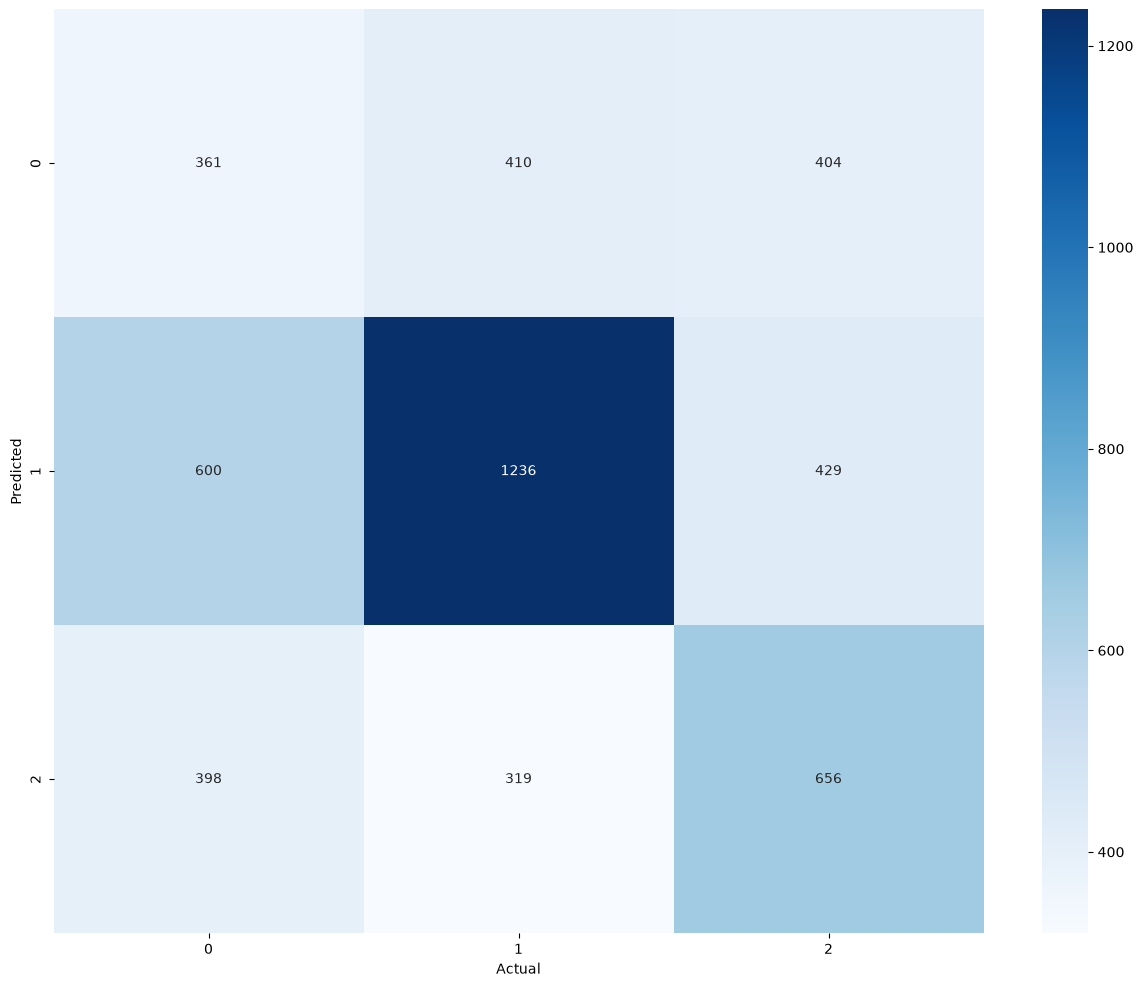

In [199]:
plt.figure(figsize=(15,12))
cm = confusion_matrix(y_test, y_hat)
sns.heatmap(cm, annot=True, fmt="d", cmap=("Blues"))
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

In [201]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Football_match_prediction")

with mlflow.start_run(run_name="Catboost experiment 6"):
    mlflow.log_input(dataset_v1_2, context="source")
    mlflow.log_params(cbc_model_6.get_params())

    mlflow.log_metrics({
        "train_accuracy": 0.55,
        "test_accuracy": 0.47,

        "precision_away": 0.44,
        "recall_away": 0.48,

        "precision_draw": 0.27,
        "recall_draw": 0.31,

        "precision_home": 0.63,
        "recall_home": 0.55,

    }
)

    mlflow.catboost.log_model(cbc_model_6, "Catboost Model 6")

2026/10/23 16:58:30 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run Catboost experiment 6 at: http://127.0.0.1:5000/#/experiments/1/runs/811f56e3b33649a8b53d75db7dffe1e2
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


### Conclusion
Experiment 9 achieved **46.81% test accuracy**, slightly exceeding Experiment 8 (46.06%) but remaining below the 50.23% achieved in Experiment 5.

Although home-win recall improved to 55% and draw recall remained relatively balanced at 31%, the overall macro F1 of **0.44** showed no meaningful improvement.

**Conclusion:** Filtering incomplete records did not produce a substantial performance improvement. Rather than continuing CatBoost hyperparameter tuning, the next stage will investigate alternative preprocessing strategies and classification algorithms, beginning with Logistic Regression.

---

## Dataset V1.2 — Feature Encoding and Numerical Scaling

**Objective:** Transform `X_train_v12` and `X_test_v12` into numerical features using `ColumnTransformer`, preparing the dataset for alternative classification algorithms.

In [203]:
cat_cols_v12 = x_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

num_cols_v12 = x_train.select_dtypes(
    include=["number"]
).columns.tolist()

C:\Users\Admin\AppData\Local\Temp\ipykernel_13128\643525264.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols_v12 = x_train.select_dtypes(


In [204]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor_v12 = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), cat_cols_v12),
    ("numerical", StandardScaler(), num_cols_v12)
])

In [205]:
x_train_processed = preprocessor_v12.fit_transform(x_train)
x_test_processed = preprocessor_v12.transform(x_test)

### Conclusion: 
 One-hot encoding was applied to categorical features to avoid artificial ordering, while `StandardScaler` standardized numerical features to support model optimization. The transformer was fitted only on the training data and applied to the test data, ensuring consistent preprocessing without data leakage.

---